# Latent Feature Extraction for Musical Genres from Raw Audio — Full Paper Reproduction

This notebook reproduces the experimental pipeline from:

**Arjun Sawhney, Vrinda Vasavada, Woody Wang — _Latent Feature Extraction for Musical Genres from Raw Audio_**

The notebook is organized in the same experimental progression as the paper:

1. Dataset preparation and raw-input PCA
2. Baseline two-layer genre classifier
3. Vanilla autoencoder
4. Deep Softmax Autoencoder
5. Quantitative evaluation
6. 64-D and 4-D embedding analysis
7. Final comparison against the paper

## Important reproduction notes

The paper specifies the dataset, four selected genres, 1-second segmentation, 500-D pooled input, model layer sizes, final-model learning rate, batch size, optimizer, and \(\gamma=0.9\).

A few details are **not fully specified in the PDF**, including the exact rule used to select 8,000 segments, baseline optimizer/training schedule, all hidden-layer activations in the deep model, and the exact placement of dropout. Those choices are clearly marked below as **reproduction assumptions** rather than claimed as paper-specified facts.

## Part A — Setup and Data Preparation

In [1]:
# Cell 1 — Install dependencies
!pip install -q kagglehub librosa tensorflow scikit-learn pandas matplotlib

In [2]:
# Cell 2 — Imports
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import tensorflow as tf
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

warnings.filterwarnings("ignore")

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.20.0
NumPy: 2.1.3


In [3]:
# Cell 3 — Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [4]:
# Cell 4 — Download GTZAN dataset from Kaggle

dataset_root = kagglehub.dataset_download(
    "andradaolteanu/gtzan-dataset-music-genre-classification"
)

base_path = os.path.join(
    dataset_root,
    "Data",
    "genres_original"
)

print("Dataset root:", dataset_root)
print("Audio path:", base_path)

Using Colab cache for faster access to the 'gtzan-dataset-music-genre-classification' dataset.
Dataset root: /kaggle/input/gtzan-dataset-music-genre-classification
Audio path: /kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original


In [5]:
# Cell 5 — Paper genre subset and labels

genres = ["classical", "jazz", "pop", "metal"]

label_map = {
    "classical": 0,
    "jazz": 1,
    "pop": 2,
    "metal": 3
}

id_to_genre = {v: k for k, v in label_map.items()}

print(label_map)

{'classical': 0, 'jazz': 1, 'pop': 2, 'metal': 3}


### Preprocessing used in the paper

The paper:
- loads raw audio amplitudes,
- splits songs into 1-second segments,
- treats each segment as approximately \(R^{20000}\),
- applies average pooling with pool size 40,
- obtains one 500-D vector per segment.

GTZAN's native rate is 22.05 kHz, while the paper describes a 20,000-value 1-second vector.  
To reproduce the stated tensor dimensions exactly, this notebook resamples to **20 kHz** before pooling.

In [6]:
# Cell 6 — Audio preprocessing function

def process_audio_file(file_path):
    # Match the paper's stated ~20,000 samples per 1-second example
    audio, sr = librosa.load(
        file_path,
        sr=20000,
        mono=True
    )

    segment_length = 20000
    n_segments = len(audio) // segment_length

    pooled_segments = []

    for i in range(n_segments):
        start = i * segment_length
        end = start + segment_length

        segment = audio[start:end]

        # 20,000 -> (500, 40) -> 500
        pooled = segment.reshape(500, 40).mean(axis=1)

        pooled_segments.append(pooled.astype(np.float32))

    return pooled_segments

In [7]:
# Cell 7 — Sanity check one audio file

test_file = os.path.join(
    base_path,
    "classical",
    "classical.00000.wav"
)

test_segments = process_audio_file(test_file)

print("Segments from test song:", len(test_segments))
print("Shape of one pooled segment:", test_segments[0].shape)
print("First 10 pooled amplitudes:", test_segments[0][:10])

Segments from test song: 30
Shape of one pooled segment: (500,)
First 10 pooled amplitudes: [ 0.01017457 -0.00297242 -0.00608414 -0.0086507  -0.0053981  -0.01044667
  0.00344308  0.02219958  0.01126564 -0.00443544]


In [8]:
# Cell 8 — Build all usable 1-second pooled examples

X_all = []
y_all = []
source_all = []
bad_files = []

for genre in genres:
    genre_dir = os.path.join(base_path, genre)
    print("Processing:", genre)

    for filename in sorted(os.listdir(genre_dir)):
        if not filename.lower().endswith(".wav"):
            continue

        file_path = os.path.join(genre_dir, filename)

        try:
            segments = process_audio_file(file_path)

            for seg_idx, segment in enumerate(segments):
                X_all.append(segment)
                y_all.append(label_map[genre])
                source_all.append((filename, seg_idx))

        except Exception as exc:
            print("Skipping unreadable file:", filename)
            bad_files.append((filename, str(exc)))

X_all = np.asarray(X_all, dtype=np.float32)
y_all = np.asarray(y_all, dtype=np.int32)
source_all = np.asarray(source_all, dtype=object)

print("\nX_all:", X_all.shape)
print("y_all:", y_all.shape)
print("Bad files:", [x[0] for x in bad_files])

Processing: classical
Processing: jazz
Skipping unreadable file: jazz.00054.wav
Processing: pop
Processing: metal

X_all: (11968, 500)
y_all: (11968,)
Bad files: ['jazz.00054.wav']


In [9]:
# Cell 9 — Inspect available examples by genre

for genre, label in label_map.items():
    print(f"{genre:10s}: {(y_all == label).sum()}")

classical : 2998
jazz      : 2970
pop       : 3000
metal     : 3000


### Reconstruct the paper's balanced 8,000-example dataset

The paper reports:
- **8,000 examples total**
- **equal number from each of the four genres**
- split into **6000 train / 1000 dev / 1000 test**

It does not state which exact 2,000 one-second segments were retained per genre.

**Reproduction assumption:** randomly choose 2,000 segments per genre using a fixed seed.

In [10]:
# Cell 10 — Select 2,000 examples per genre = 8,000 total

rng = np.random.default_rng(SEED)

selected_indices = []

for label in range(4):
    indices = np.where(y_all == label)[0]

    chosen = rng.choice(
        indices,
        size=2000,
        replace=False
    )

    selected_indices.extend(chosen.tolist())

selected_indices = np.asarray(selected_indices)

X = X_all[selected_indices]
y = y_all[selected_indices]
sources = source_all[selected_indices]

# Shuffle the balanced dataset before splitting
perm = rng.permutation(len(X))
X = X[perm]
y = y[perm]
sources = sources[perm]

print("X:", X.shape)
print("y:", y.shape)
print("Class counts:", np.unique(y, return_counts=True))

X: (8000, 500)
y: (8000,)
Class counts: (array([0, 1, 2, 3], dtype=int32), array([2000, 2000, 2000, 2000]))


In [11]:
# Cell 11 — Train / Validation / Test split: 6000 / 1000 / 1000

X_train, X_tmp, y_train, y_tmp = train_test_split(
    X,
    y,
    train_size=6000,
    test_size=2000,
    stratify=y,
    random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_tmp,
    y_tmp,
    train_size=1000,
    test_size=1000,
    stratify=y_tmp,
    random_state=SEED
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nTrain counts:", np.unique(y_train, return_counts=True)[1])
print("Val counts:", np.unique(y_val, return_counts=True)[1])
print("Test counts:", np.unique(y_test, return_counts=True)[1])

Train: (6000, 500) (6000,)
Validation: (1000, 500) (1000,)
Test: (1000, 500) (1000,)

Train counts: [1500 1500 1500 1500]
Val counts: [250 250 250 250]
Test counts: [250 250 250 250]


## Part B — Figure 1: PCA of Raw 500-D Input

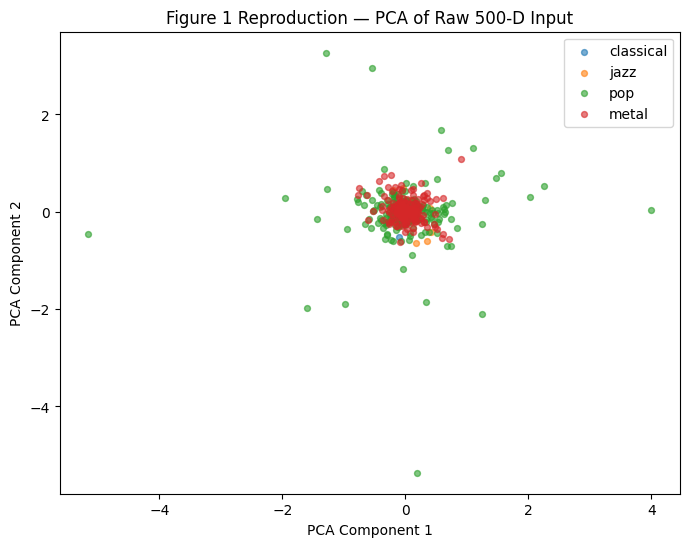

Explained variance ratio: [0.0204246  0.01909081]


In [12]:
# Cell 12 — PCA on raw pooled input

raw_pca = PCA(n_components=2, random_state=SEED)
raw_test_2d = raw_pca.fit_transform(X_test)

plt.figure(figsize=(8, 6))

for label, genre in enumerate(genres):
    idx = y_test == label
    plt.scatter(
        raw_test_2d[idx, 0],
        raw_test_2d[idx, 1],
        s=18,
        alpha=0.6,
        label=genre
    )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Figure 1 Reproduction — PCA of Raw 500-D Input")
plt.legend()
plt.show()

print("Explained variance ratio:", raw_pca.explained_variance_ratio_)

## Part C — Experiment 1: Baseline Two-Layer Neural Network

The paper's baseline classifier is:

\[
500 \rightarrow 128 \;(\tanh) \rightarrow 4
\]

with multiclass cross-entropy loss.

The PDF does **not** fully specify the baseline optimizer, learning rate, batch size, or number of epochs.

**Reproduction assumption for training only:** Adam, learning rate \(10^{-3}\), batch size 32, 50 epochs.

In [13]:
# Cell 13 — Build baseline classifier

tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

baseline_input = tf.keras.layers.Input(shape=(500,), name="baseline_input")

baseline_hidden = tf.keras.layers.Dense(
    128,
    activation="tanh",
    name="baseline_hidden_128"
)(baseline_input)

baseline_logits = tf.keras.layers.Dense(
    4,
    name="baseline_logits"
)(baseline_hidden)

baseline_model = tf.keras.Model(
    inputs=baseline_input,
    outputs=baseline_logits,
    name="baseline_two_layer_nn"
)

baseline_model.summary()

Model: "baseline_two_layer_nn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ baseline_input (InputLayer)     │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ baseline_hidden_128 (Dense)     │ (None, 128)            │        64,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ baseline_logits (Dense)         │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,644 (252.52 KB)

 Trainable params: 64,644 (252.52 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Cell 14 — Compile baseline

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

In [15]:
# Cell 15 — Train baseline

baseline_history = baseline_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3095 - loss: 1.4008 - val_accuracy: 0.3130 - val_loss: 1.3865
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4342 - loss: 1.3502 - val_accuracy: 0.3570 - val_loss: 1.3961
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4588 - loss: 1.3290 - val_accuracy: 0.3750 - val_loss: 1.4070
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4688 - loss: 1.3143 - val_accuracy: 0.3830 - val_loss: 1.4165
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4740 - loss: 1.3030 - val_accuracy: 0.3870 - val_loss: 1.4241
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4813 - loss: 1.2939 - val_accuracy: 0.3870 - val_loss: 1.4303
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4857 - loss: 1.2863 - val_accuracy: 0.3910 - val_loss: 1.4353
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4867 - loss: 1.2798 - val_accuracy: 0.

In [16]:
# Cell 16 — Baseline train / validation / test accuracy

baseline_train = baseline_model.evaluate(X_train, y_train, verbose=0, return_dict=True)
baseline_val = baseline_model.evaluate(X_val, y_val, verbose=0, return_dict=True)
baseline_test = baseline_model.evaluate(X_test, y_test, verbose=0, return_dict=True)

print("BASELINE TWO-LAYER NEURAL NETWORK")
print("---------------------------------")
print(f"Train Accuracy      : {baseline_train['accuracy'] * 100:.2f}%")
print(f"Validation Accuracy : {baseline_val['accuracy'] * 100:.2f}%")
print(f"Test Accuracy       : {baseline_test['accuracy'] * 100:.2f}%")

BASELINE TWO-LAYER NEURAL NETWORK
---------------------------------
Train Accuracy      : 75.42%
Validation Accuracy : 50.50%
Test Accuracy       : 47.50%


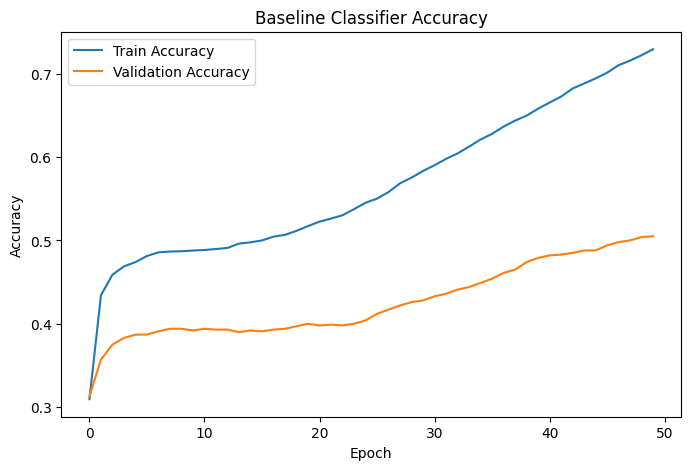

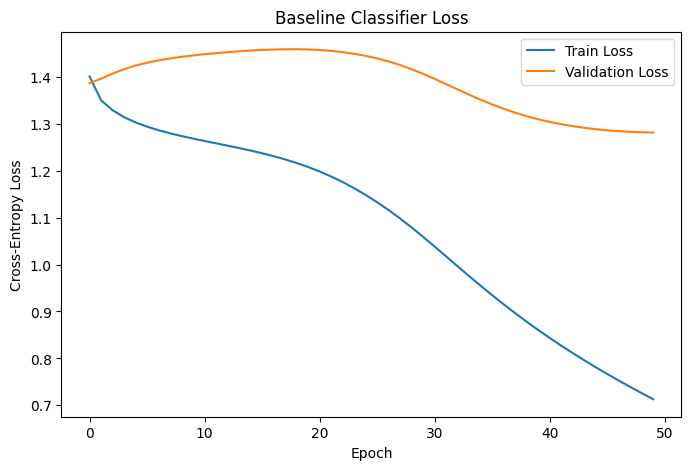

In [17]:
# Cell 17 — Baseline learning curves

plt.figure(figsize=(8, 5))
plt.plot(baseline_history.history["accuracy"], label="Train Accuracy")
plt.plot(baseline_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline Classifier Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(baseline_history.history["loss"], label="Train Loss")
plt.plot(baseline_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Baseline Classifier Loss")
plt.legend()
plt.show()

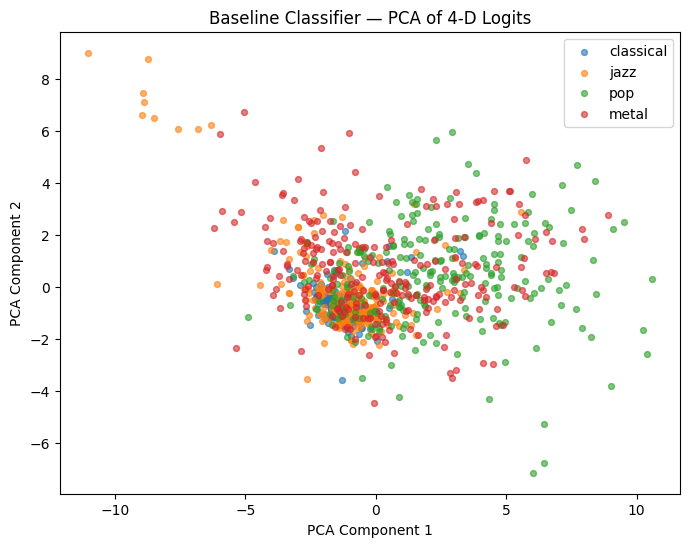

In [18]:
# Cell 18 — Baseline 4-D logits and PCA

baseline_test_logits = baseline_model.predict(X_test, verbose=0)

baseline_logit_pca = PCA(n_components=2, random_state=SEED)
baseline_logits_2d = baseline_logit_pca.fit_transform(baseline_test_logits)

plt.figure(figsize=(8, 6))

for label, genre in enumerate(genres):
    idx = y_test == label
    plt.scatter(
        baseline_logits_2d[idx, 0],
        baseline_logits_2d[idx, 1],
        s=18,
        alpha=0.6,
        label=genre
    )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Baseline Classifier — PCA of 4-D Logits")
plt.legend()
plt.show()

## Part D — Experiment 2: Vanilla Autoencoder

The paper's deeper vanilla autoencoder is the autoencoding branch of Figure 2:

\[
500 \rightarrow 256 \rightarrow 192 \rightarrow 128 \rightarrow 64
\rightarrow 128 \rightarrow 192 \rightarrow 256 \rightarrow 500
\]

The 64-D layer is the latent encoding.

The paper defines reconstruction loss as:

\[
L_{reconstruction} = \lVert x - g(f(x)) \rVert_2^2
\]

### Activation assumption
The PDF gives the layer sizes but does not explicitly state every hidden-layer activation in the deep autoencoder.  
This reproduction uses **tanh** hidden activations and a linear reconstruction output. This is an implementation assumption, not a directly stated paper detail.

In [19]:
# Cell 19 — Build vanilla autoencoder

tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

ae_input = tf.keras.layers.Input(shape=(500,), name="ae_input")

x = tf.keras.layers.Dense(256, activation="tanh", name="ae_enc_256")(ae_input)
x = tf.keras.layers.Dense(192, activation="tanh", name="ae_enc_192")(x)
x = tf.keras.layers.Dense(128, activation="tanh", name="ae_enc_128")(x)

ae_latent = tf.keras.layers.Dense(
    64,
    activation="tanh",
    name="ae_latent_64"
)(x)

x = tf.keras.layers.Dense(128, activation="tanh", name="ae_dec_128")(ae_latent)
x = tf.keras.layers.Dense(192, activation="tanh", name="ae_dec_192")(x)
x = tf.keras.layers.Dense(256, activation="tanh", name="ae_dec_256")(x)

ae_reconstruction = tf.keras.layers.Dense(
    500,
    activation=None,
    name="ae_reconstruction"
)(x)

vanilla_autoencoder = tf.keras.Model(
    inputs=ae_input,
    outputs=ae_reconstruction,
    name="vanilla_autoencoder"
)

vanilla_encoder = tf.keras.Model(
    inputs=ae_input,
    outputs=ae_latent,
    name="vanilla_encoder"
)

vanilla_autoencoder.summary()

Model: "vanilla_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ae_input (InputLayer)           │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_enc_256 (Dense)              │ (None, 256)            │       128,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_enc_192 (Dense)              │ (None, 192)            │        49,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_enc_128 (Dense)              │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_latent_64 (Dense)            │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_dec_128 (Dense)              │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_dec_192 (Dense)              │ (None, 192)            │        24,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_dec_256 (Dense)              │ (None, 256)            │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_reconstruction (Dense)       │ (None, 500)            │       128,500 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,556 (1.61 MB)

 Trainable params: 421,556 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Cell 20 — Exact squared L2 reconstruction loss

def squared_l2_reconstruction_loss(y_true, y_pred):
    per_example = tf.reduce_sum(
        tf.square(y_true - y_pred),
        axis=1
    )
    return tf.reduce_mean(per_example)

The paper's Figure 2 shows **Adam**, learning rate **0.0001**, and batch size **512** for the deep architecture.  
The paper does not clearly state a separate vanilla-autoencoder epoch count.

**Reproduction assumption:** 500 epochs, matching the approximate training horizon shown for the final deep model.

In [21]:
# Cell 21 — Compile vanilla autoencoder

vanilla_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=squared_l2_reconstruction_loss
)

In [22]:
# Cell 22 — Train vanilla autoencoder

vanilla_history = vanilla_autoencoder.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    batch_size=512,
    epochs=500,
    verbose=1
)

Epoch 1/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 7.6216 - val_loss: 6.7951
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 6.7152 - val_loss: 6.2044
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 6.2431 - val_loss: 5.8676
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 5.9626 - val_loss: 5.6532
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 5.7765 - val_loss: 5.5035
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 5.6413 - val_loss: 5.3908
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 5.5357 - val_loss: 5.3007
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 5.4483 - val_loss: 5.2253
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 5.3727 - val_loss: 5.1597
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 5.3049 - val_loss: 5.1011
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 5.2426 - val_loss: 5.0476
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step

In [23]:
# Cell 23 — Vanilla autoencoder reconstruction losses

vanilla_train_loss = vanilla_autoencoder.evaluate(X_train, X_train, verbose=0)
vanilla_val_loss = vanilla_autoencoder.evaluate(X_val, X_val, verbose=0)
vanilla_test_loss = vanilla_autoencoder.evaluate(X_test, X_test, verbose=0)

print("VANILLA AUTOENCODER")
print("-------------------")
print(f"Train Reconstruction Loss      : {vanilla_train_loss:.6f}")
print(f"Validation Reconstruction Loss : {vanilla_val_loss:.6f}")
print(f"Test Reconstruction Loss       : {vanilla_test_loss:.6f}")

VANILLA AUTOENCODER
-------------------
Train Reconstruction Loss      : 3.219483
Validation Reconstruction Loss : 3.448041
Test Reconstruction Loss       : 3.463803


In [24]:
# Cell 24 — Extract 64-D vanilla-autoencoder embeddings

vanilla_train_embeddings = vanilla_encoder.predict(X_train, batch_size=512, verbose=0)
vanilla_val_embeddings = vanilla_encoder.predict(X_val, batch_size=512, verbose=0)
vanilla_test_embeddings = vanilla_encoder.predict(X_test, batch_size=512, verbose=0)

print("Train:", vanilla_train_embeddings.shape)
print("Validation:", vanilla_val_embeddings.shape)
print("Test:", vanilla_test_embeddings.shape)

Train: (6000, 64)
Validation: (1000, 64)
Test: (1000, 64)


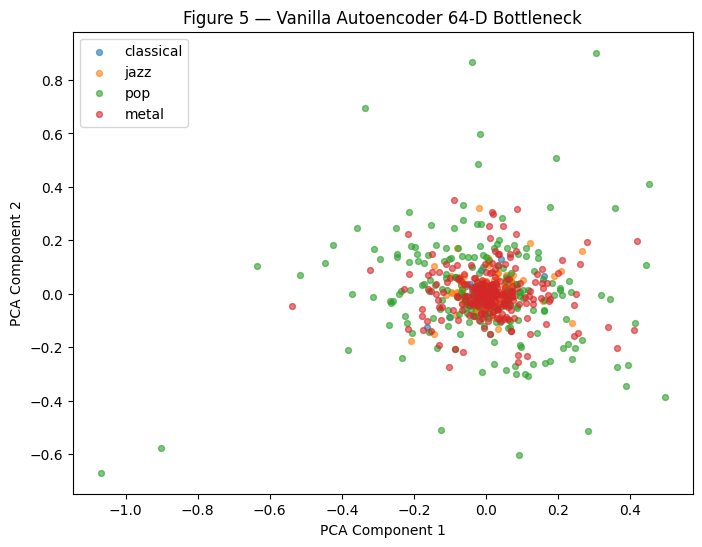

In [25]:
# Cell 25 — Figure 5 left: PCA of vanilla 64-D bottleneck

vanilla_pca = PCA(n_components=2, random_state=SEED)
vanilla_embeddings_2d = vanilla_pca.fit_transform(vanilla_test_embeddings)

plt.figure(figsize=(8, 6))

for label, genre in enumerate(genres):
    idx = y_test == label
    plt.scatter(
        vanilla_embeddings_2d[idx, 0],
        vanilla_embeddings_2d[idx, 1],
        s=18,
        alpha=0.6,
        label=genre
    )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Figure 5 — Vanilla Autoencoder 64-D Bottleneck")
plt.legend()
plt.show()

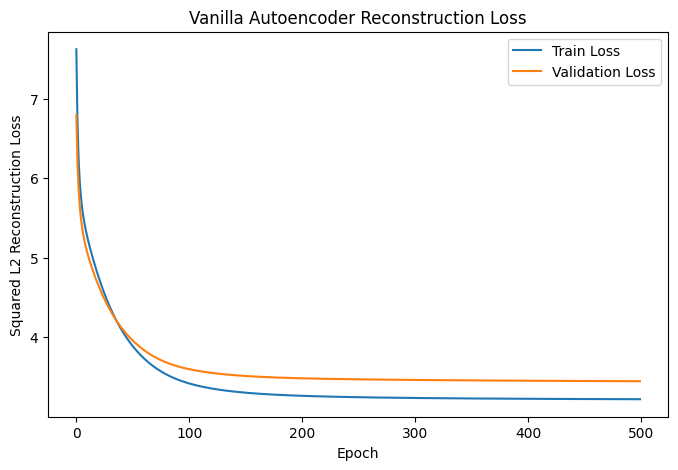

In [26]:
# Cell 26 — Vanilla autoencoder loss curve

plt.figure(figsize=(8, 5))
plt.plot(vanilla_history.history["loss"], label="Train Loss")
plt.plot(vanilla_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Squared L2 Reconstruction Loss")
plt.title("Vanilla Autoencoder Reconstruction Loss")
plt.legend()
plt.show()

## Part E — Experiment 3: Deep Softmax Autoencoder (Final Model)

The final model combines the autoencoder and classifier.

### Shared encoder
\[
500 \rightarrow 256 \rightarrow 192 \rightarrow 128 \rightarrow 64
\]

### Decoder
\[
64 \rightarrow 128 \rightarrow 192 \rightarrow 256 \rightarrow 500
\]

### Genre classifier
\[
64 \rightarrow 32 \rightarrow 16 \rightarrow 4
\]

### Joint loss
\[
L =
\gamma L_{reconstruction}
+
(1-\gamma)L_{classification}
\]

with:

\[
\gamma = 0.9
\]

The paper also reports a final dropout keep probability of 0.9.

### Activation/dropout placement assumption
The PDF does not explicitly specify every hidden activation or the exact dropout placement.  
This reproduction uses **tanh** hidden activations and `Dropout(0.1)` after hidden encoder/classifier layers, corresponding to keep probability 0.9.

In [27]:
# Cell 27 — Build Deep Softmax Autoencoder

tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

deep_input = tf.keras.layers.Input(
    shape=(500,),
    name="audio_input"
)

# Encoder
e = tf.keras.layers.Dense(256, activation="tanh", name="enc_256")(deep_input)
e = tf.keras.layers.Dropout(0.1, name="enc_dropout_256")(e)

e = tf.keras.layers.Dense(192, activation="tanh", name="enc_192")(e)
e = tf.keras.layers.Dropout(0.1, name="enc_dropout_192")(e)

e = tf.keras.layers.Dense(128, activation="tanh", name="enc_128")(e)
e = tf.keras.layers.Dropout(0.1, name="enc_dropout_128")(e)

deep_latent = tf.keras.layers.Dense(
    64,
    activation="tanh",
    name="latent_encoding"
)(e)

# Decoder branch
d = tf.keras.layers.Dense(128, activation="tanh", name="dec_128")(deep_latent)
d = tf.keras.layers.Dense(192, activation="tanh", name="dec_192")(d)
d = tf.keras.layers.Dense(256, activation="tanh", name="dec_256")(d)

deep_reconstruction = tf.keras.layers.Dense(
    500,
    activation=None,
    name="reconstruction"
)(d)

# Classifier branch
c = tf.keras.layers.Dense(32, activation="tanh", name="clf_32")(deep_latent)
c = tf.keras.layers.Dropout(0.1, name="clf_dropout_32")(c)

c = tf.keras.layers.Dense(16, activation="tanh", name="clf_16")(c)
c = tf.keras.layers.Dropout(0.1, name="clf_dropout_16")(c)

deep_logits = tf.keras.layers.Dense(
    4,
    activation=None,
    name="genre_prediction"
)(c)

deep_model = tf.keras.Model(
    inputs=deep_input,
    outputs=[deep_reconstruction, deep_logits],
    name="deep_softmax_autoencoder"
)

deep_encoder = tf.keras.Model(
    inputs=deep_input,
    outputs=deep_latent,
    name="deep_encoder"
)

deep_logit_encoder = tf.keras.Model(
    inputs=deep_input,
    outputs=deep_logits,
    name="deep_logit_encoder"
)

deep_model.summary()

Model: "deep_softmax_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ audio_input         │ (None, 500)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_256 (Dense)     │ (None, 256)       │    128,256 │ audio_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_dropout_256     │ (None, 256)       │          0 │ enc_256[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_192 (Dense)     │ (None, 192)       │     49,344 │ enc_dropout_256[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_dropout_192     │ (None, 192)       │          0 │ enc_192[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_128 (Dense)     │ (None, 128)       │     24,704 │ enc_dropout_192[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_dropout_128     │ (None, 128)       │          0 │ enc_128[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent_encoding     │ (None, 64)        │      8,256 │ enc_dropout_128[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clf_32 (Dense)      │ (None, 32)        │      2,080 │ latent_encoding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_128 (Dense)     │ (None, 128)       │      8,320 │ latent_encoding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clf_dropout_32      │ (None, 32)        │          0 │ clf_32[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_192 (Dense)     │ (None, 192)       │     24,768 │ dec_128[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clf_16 (Dense)      │ (None, 16)        │        528 │ clf_dropout_32[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_256 (Dense)     │ (None, 256)       │     49,408 │ dec_192[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clf_dropout_16      │ (None, 16)        │          0 │ clf_16[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reconstruction      │ (None, 500)       │    128,500 │ dec_256[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ genre_prediction    │ (None, 4)         │         68 │ clf_dropout_16[0… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 424,232 (1.62 MB)

 Trainable params: 424,232 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
# Cell 28 — Joint objective and optimizer

GAMMA = 0.9

classification_loss = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

deep_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),

    loss={
        "reconstruction": squared_l2_reconstruction_loss,
        "genre_prediction": classification_loss
    },

    loss_weights={
        "reconstruction": GAMMA,
        "genre_prediction": 1.0 - GAMMA
    },

    metrics={
        "genre_prediction": ["accuracy"]
    }
)

In [29]:
# Cell 29 — Train final Deep Softmax Autoencoder

deep_history = deep_model.fit(
    X_train,

    {
        "reconstruction": X_train,
        "genre_prediction": y_train
    },

    validation_data=(
        X_val,
        {
            "reconstruction": X_val,
            "genre_prediction": y_val
        }
    ),

    batch_size=512,
    epochs=500,
    verbose=1
)

Epoch 1/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - genre_prediction_accuracy: 0.2625 - genre_prediction_loss: 1.4249 - loss: 7.3416 - reconstruction_loss: 7.9959 - val_genre_prediction_accuracy: 0.2730 - val_genre_prediction_loss: 1.4056 - val_loss: 6.1016 - val_reconstruction_loss: 6.6293
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - genre_prediction_accuracy: 0.2783 - genre_prediction_loss: 1.4168 - loss: 6.5297 - reconstruction_loss: 7.0988 - val_genre_prediction_accuracy: 0.2840 - val_genre_prediction_loss: 1.4028 - val_loss: 5.6294 - val_reconstruction_loss: 6.1046
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - genre_prediction_accuracy: 0.2972 - genre_prediction_loss: 1.4163 - loss: 6.0594 - reconstruction_loss: 6.5768 - val_genre_prediction_accuracy: 0.2920 - val_genre_prediction_loss: 1.4005 - val_loss: 5.3585 - val_reconstruction_loss: 5.8037
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - genre_prediction_accuracy: 0.3025 - genre_prediction_loss: 1.41

In [30]:
# Cell 30 — Evaluate final model on all three splits

deep_train_results = deep_model.evaluate(
    X_train,
    {
        "reconstruction": X_train,
        "genre_prediction": y_train
    },
    verbose=0,
    return_dict=True
)

deep_val_results = deep_model.evaluate(
    X_val,
    {
        "reconstruction": X_val,
        "genre_prediction": y_val
    },
    verbose=0,
    return_dict=True
)

deep_test_results = deep_model.evaluate(
    X_test,
    {
        "reconstruction": X_test,
        "genre_prediction": y_test
    },
    verbose=0,
    return_dict=True
)

deep_train_acc = deep_train_results["genre_prediction_accuracy"]
deep_val_acc = deep_val_results["genre_prediction_accuracy"]
deep_test_acc = deep_test_results["genre_prediction_accuracy"]

print("DEEP SOFTMAX AUTOENCODER")
print("------------------------")
print(f"Train Accuracy      : {deep_train_acc * 100:.2f}%")
print(f"Validation Accuracy : {deep_val_acc * 100:.2f}%")
print(f"Test Accuracy       : {deep_test_acc * 100:.2f}%")

DEEP SOFTMAX AUTOENCODER
------------------------
Train Accuracy      : 48.17%
Validation Accuracy : 42.80%
Test Accuracy       : 42.30%


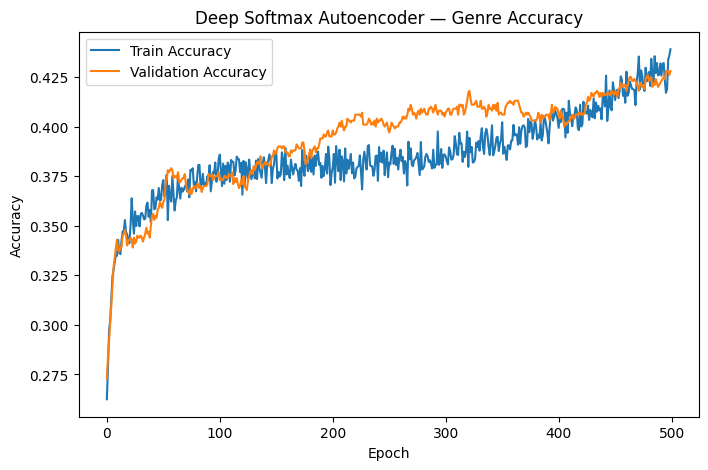

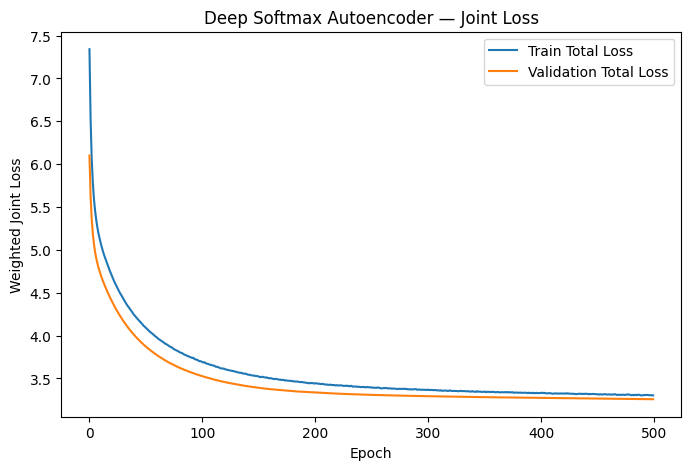

In [31]:
# Cell 31 — Final-model learning curves

plt.figure(figsize=(8, 5))
plt.plot(
    deep_history.history["genre_prediction_accuracy"],
    label="Train Accuracy"
)
plt.plot(
    deep_history.history["val_genre_prediction_accuracy"],
    label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Deep Softmax Autoencoder — Genre Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(deep_history.history["loss"], label="Train Total Loss")
plt.plot(deep_history.history["val_loss"], label="Validation Total Loss")
plt.xlabel("Epoch")
plt.ylabel("Weighted Joint Loss")
plt.title("Deep Softmax Autoencoder — Joint Loss")
plt.legend()
plt.show()

## Part F — Final Model Quantitative Evaluation

In [32]:
# Cell 32 — Generate final test predictions

test_reconstruction, deep_test_logits = deep_model.predict(
    X_test,
    batch_size=512,
    verbose=0
)

deep_y_pred = np.argmax(deep_test_logits, axis=1)

print("Predictions:", deep_y_pred.shape)
print("Test accuracy:", accuracy_score(y_test, deep_y_pred))

Predictions: (1000,)
Test accuracy: 0.423


In [33]:
# Cell 33 — Precision / Recall / F1 by genre

print(
    classification_report(
        y_test,
        deep_y_pred,
        target_names=genres,
        digits=3
    )
)

precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    deep_y_pred,
    labels=[0, 1, 2, 3],
    zero_division=0
)

per_class_metrics = pd.DataFrame({
    "Genre": genres,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Support": support
})

per_class_metrics

              precision    recall  f1-score   support

   classical      0.396     0.968     0.562       250
        jazz      0.263     0.084     0.127       250
         pop      0.574     0.448     0.503       250
       metal      0.421     0.192     0.264       250

    accuracy                          0.423      1000
   macro avg      0.413     0.423     0.364      1000
weighted avg      0.413     0.423     0.364      1000



,Genre,Precision,Recall,F1,Support
0,classical,0.396072,0.968,0.562137,250
1,jazz,0.262500,0.084,0.127273,250
2,pop,0.574359,0.448,0.503371,250
3,metal,0.421053,0.192,0.263736,250


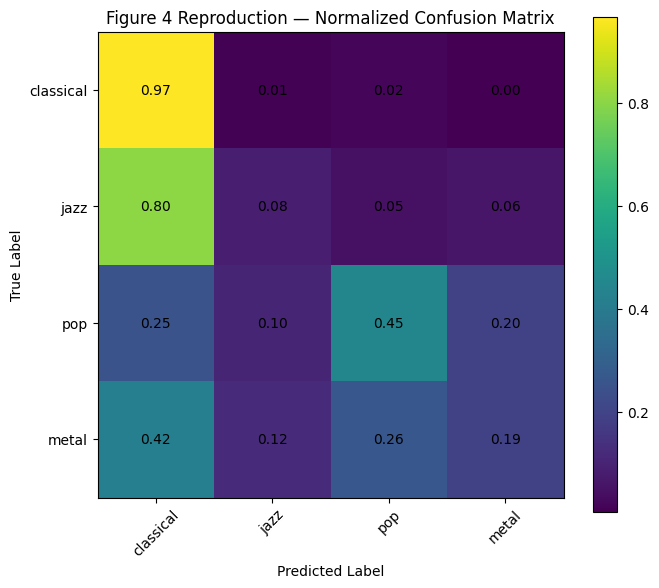

In [34]:
# Cell 34 — Figure 4: normalized confusion matrix

cm = confusion_matrix(
    y_test,
    deep_y_pred,
    normalize="true"
)

plt.figure(figsize=(7, 6))
plt.imshow(cm)

plt.xticks(range(4), genres, rotation=45)
plt.yticks(range(4), genres)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Figure 4 Reproduction — Normalized Confusion Matrix")
plt.colorbar()

for i in range(4):
    for j in range(4):
        plt.text(
            j,
            i,
            f"{cm[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

## Part G — Final Model Qualitative Embedding Evaluation

In [35]:
# Cell 35 — Extract 64-D final-model bottleneck embeddings

deep_train_embeddings = deep_encoder.predict(X_train, batch_size=512, verbose=0)
deep_val_embeddings = deep_encoder.predict(X_val, batch_size=512, verbose=0)
deep_test_embeddings = deep_encoder.predict(X_test, batch_size=512, verbose=0)

print("Train:", deep_train_embeddings.shape)
print("Validation:", deep_val_embeddings.shape)
print("Test:", deep_test_embeddings.shape)

Train: (6000, 64)
Validation: (1000, 64)
Test: (1000, 64)


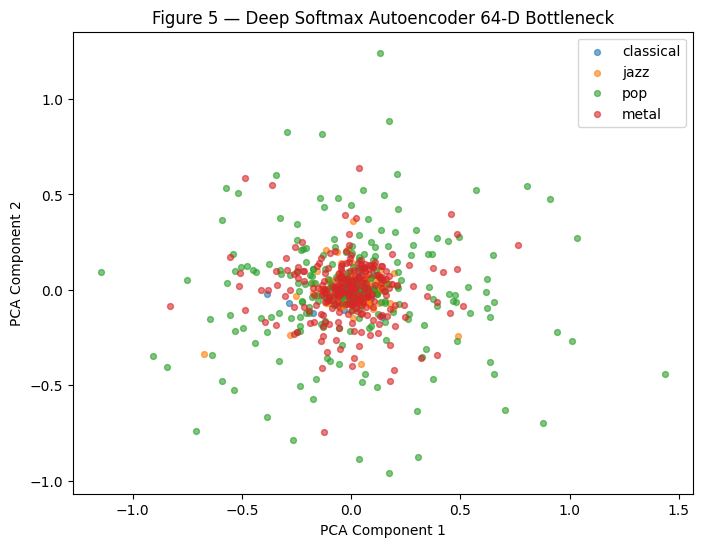

In [36]:
# Cell 36 — Figure 5 right: PCA of Deep Softmax 64-D bottleneck

deep_64_pca = PCA(n_components=2, random_state=SEED)
deep_embeddings_2d = deep_64_pca.fit_transform(deep_test_embeddings)

plt.figure(figsize=(8, 6))

for label, genre in enumerate(genres):
    idx = y_test == label
    plt.scatter(
        deep_embeddings_2d[idx, 0],
        deep_embeddings_2d[idx, 1],
        s=18,
        alpha=0.6,
        label=genre
    )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Figure 5 — Deep Softmax Autoencoder 64-D Bottleneck")
plt.legend()
plt.show()

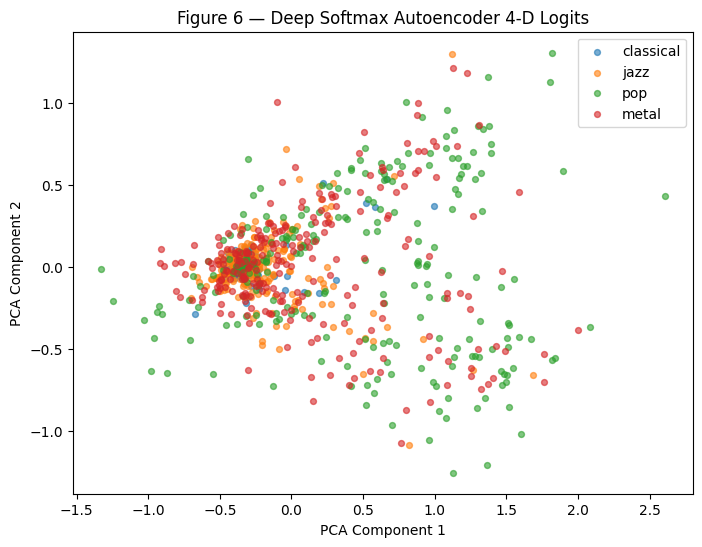

In [37]:
# Cell 37 — Figure 6: PCA of Deep Softmax 4-D logits

deep_test_logits_for_pca = deep_logit_encoder.predict(
    X_test,
    batch_size=512,
    verbose=0
)

deep_4_pca = PCA(n_components=2, random_state=SEED)
deep_logits_2d = deep_4_pca.fit_transform(deep_test_logits_for_pca)

plt.figure(figsize=(8, 6))

for label, genre in enumerate(genres):
    idx = y_test == label
    plt.scatter(
        deep_logits_2d[idx, 0],
        deep_logits_2d[idx, 1],
        s=18,
        alpha=0.6,
        label=genre
    )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Figure 6 — Deep Softmax Autoencoder 4-D Logits")
plt.legend()
plt.show()

## Part H — Final Comparison

In [38]:
# Cell 38 — Baseline vs final model: reproduced results

reproduced_comparison = pd.DataFrame({
    "Model": [
        "Baseline Two-Layer NN",
        "Deep Softmax Autoencoder"
    ],
    "Train Accuracy (%)": [
        baseline_train["accuracy"] * 100,
        deep_train_acc * 100
    ],
    "Validation Accuracy (%)": [
        baseline_val["accuracy"] * 100,
        deep_val_acc * 100
    ],
    "Test Accuracy (%)": [
        baseline_test["accuracy"] * 100,
        deep_test_acc * 100
    ]
})

reproduced_comparison.round(2)

,Model,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%)
0,Baseline Two-Layer NN,75.42,50.5,47.5
1,Deep Softmax Autoencoder,48.17,42.8,42.3


In [39]:
# Cell 39 — Paper reference values

paper_reference = pd.DataFrame({
    "Model": [
        "Baseline Two-Layer NN",
        "Deep Softmax Autoencoder"
    ],
    "Paper Train Accuracy (%)": [52.0, 94.9],
    "Paper Dev Accuracy (%)": [38.1, 64.1],
    "Paper Test Accuracy (%)": [36.4, 65.3]
})

paper_reference

,Model,Paper Train Accuracy (%),Paper Dev Accuracy (%),Paper Test Accuracy (%)
0,Baseline Two-Layer NN,52.0,38.1,36.4
1,Deep Softmax Autoencoder,94.9,64.1,65.3


In [40]:
# Cell 40 — Reproduction vs paper side-by-side

final_comparison = reproduced_comparison.merge(
    paper_reference,
    on="Model"
)

final_comparison.round(2)

,Model,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Paper Train Accuracy (%),Paper Dev Accuracy (%),Paper Test Accuracy (%)
0,Baseline Two-Layer NN,75.42,50.5,47.5,52.0,38.1,36.4
1,Deep Softmax Autoencoder,48.17,42.8,42.3,94.9,64.1,65.3


In [41]:
# Cell 41 — Paper's reported final per-class metrics

paper_class_metrics = pd.DataFrame({
    "Genre": ["classical", "jazz", "metal", "pop"],
    "Paper Precision": [0.783, 0.606, 0.515, 0.670],
    "Paper Recall": [0.775, 0.627, 0.554, 0.608],
    "Paper F1": [0.779, 0.616, 0.5337, 0.638]
})

paper_class_metrics

,Genre,Paper Precision,Paper Recall,Paper F1
0,classical,0.783,0.775,0.7790
1,jazz,0.606,0.627,0.6160
2,metal,0.515,0.554,0.5337
3,pop,0.670,0.608,0.6380


## Part I — Reproduction Checklist

At this point the notebook has reproduced the paper's full experimental flow:

- [x] Four GTZAN genres: classical, jazz, pop, metal
- [x] Raw waveform loading
- [x] 1-second segmentation
- [x] Average pooling to 500 dimensions
- [x] Balanced 8,000-example dataset
- [x] 6000 / 1000 / 1000 train-dev-test split
- [x] PCA of raw input
- [x] Baseline two-layer classifier
- [x] Baseline 4-D logit visualization
- [x] Vanilla autoencoder
- [x] 64-D vanilla bottleneck
- [x] PCA of vanilla bottleneck
- [x] Deep Softmax Autoencoder
- [x] Weighted reconstruction + classification loss
- [x] \(\gamma=0.9\)
- [x] Train / validation / test accuracy
- [x] Precision / recall / F1
- [x] Confusion matrix
- [x] PCA of final 64-D bottleneck
- [x] PCA of final 4-D logits
- [x] Comparison against paper-reported values

### What is exact vs assumed

**Directly specified by the paper**
- Dataset family and four genres
- Raw-audio approach
- 1-second segmentation
- Average pooling and 500-D input
- 64-D latent representation
- Baseline `500 → 128 → 4`, with `tanh`
- Deep architecture layer sizes
- Reconstruction + classification objective
- \(\gamma=0.9\)
- Adam, learning rate \(10^{-4}\), batch size 512 for the deep architecture
- dropout keep probability 0.9 after tuning
- evaluation metrics and PCA analyses

**Reproduction assumptions because the PDF does not fully specify them**
- exact 2,000 selected segments per genre
- split seed
- baseline optimizer / LR / batch size / epoch count
- all deep-model hidden activations
- precise dropout placement
- exact vanilla-autoencoder epoch count

If reproduced values differ from the paper, report the difference instead of forcing the output to match.